## Pegasus Evaluation: Depth

Section B.3. Setup, methods and metrics: `2a_base_case.ipynb`; parameters: `pegasus/evaluation_setup.py`.
B.3 runs on `tree_source`.

In [1]:
# Data source of B.3:
# - "real": the fork-join trees measured on the second testbed machine (statics/results_milos_v2/b3-vm/, VM_TREE_SETS in pegasus/real_data.py)
# - "synthetic": balanced trees of the three generated services of B.1, with a simulated ground truth (pegasus/trees.py)
tree_source = "real"

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
import pandas as pd
from pegasus.figures import math_label, sweep_table, time_table
p_label = math_label(p_label)   # the quantile name in the math notation of the paper, e.g. $P_{95}$, for the figures and the text
# synthetic trees reuse the configurations and the training data of the synthetic base case of B.1, read from
# statics/evaluation_cache/ or computed here (b1_base); the measured trees need no base case
if tree_source == "synthetic":
    globals().update(b1_base("synthetic"))
print(f"{tree_source} trees, {len(seeds)} seeds")

real trees, 3 seeds


### B.3 Varying Depth of a Map-Reduce Application

Fork-join trees: the leaves alternate between two detectors, every inner service is an aggregator; every frame goes to
all leaves, and the root releases it once both children of every aggregator have. A *balanced* tree with $h$ levels
(`tree_levels`) has $2^h - 1$ services, because every aggregator has two children, so level $i$ holds $2^{i-1}$ services.
Every method bounds each leaf-to-root path and takes the maximum over the paths (`compare_tree_methods`).

- **Real (`tree_source = "real"`):** the balanced trees measured on the second testbed machine, a virtual machine
  with 75 cores (`statics/results_milos_v2/b3-vm/`; object and face detector as leaves, image transformer as
  aggregator, one worker and 1.5 cores each, 8 configurations repeated 6 times per tree). The first machine had too
  few cores for the deeper trees: its services slowed each other down there, so their processing times were far
  from those of the benchmarks. Two tree sets (`VM_TREE_SETS` in `pegasus/real_data.py`), each with its own figure:
  - *Large trees* (the main set), image resolutions 288 to 640 px, $h$ = 1 to 6: 8 configurations drawn anew for every
    $h$. The arrival rates are low enough that the camera, which sends every frame to all leaves, keeps up at every $h$.
    A tree that the campaign is still measuring is a preliminary point, marked † (`tree_preliminary`): it is
    evaluated on the runs it has so far, and computed anew as further runs arrive.
  - *Small trees* (a check), 160 to 256 px, $h$ = 1 to 4: the same 8 configurations at every $h$. Deeper small trees
    are left out: at their higher arrival rates the camera falls behind in sending the frames to the 16 or 32 leaves.

  Every service type is trained on the grid benchmark of the same machine (`VM_TREE_BENCHMARKS`), which measured every
  configuration of the service alone: the face detector and the image transformer on the 1.5-core grid (`grid15-*`),
  whose processing times match those in the trees, and the object detector on the 8-core grid (`grid-*`), because the
  1.5-core grid does not contain it. The handling overhead of a service that receives its frames from another service
  is measured on the other trees of the set (`tree_handling_overhead`). Held-out runs: throttled for less than
  `TREE_THROTTLE_LIMIT` of their CPU periods at every node.

  Even on this machine, the services of the deepest trees process an item more slowly than in their benchmark
  (no method corrects for this), so a growing underestimate with $h$ is a property of the testbed, not
  only of a method.
- **Synthetic (`tree_source = "synthetic"`):** balanced trees of the three services of B.1, Poisson arrivals at
  `tree_utilization` of the slowest service.
- **Methods:** as in B.1 without DNN Sum; both versions of Pegasus.

Figures: `figures/tsc/b3_trees_real_<tree set>` (real) and `figures/tsc/b3_trees_synthetic` (tightness, training and
evaluation time).

In [2]:
# the options of the data source of B.3
tree_setup = configure(tree_source)
if "B.3" in tree_setup["skipped"]:
    print("B.3 skipped: not supported by the {} data".format(tree_source))
else:
    tree_levels = tree_setup["tree_levels"]
    tree_seeds = tree_setup["tree_seeds"]   # the seeds of every experiment
    # (tree set, levels h) -> valid runs so far of a tree that the campaign is still measuring (real data only)
    tree_preliminary = tree_setup.get("tree_preliminary") or {}
    # B.3: balanced fork-join trees, (shape, levels) -> (children, the service type or node of every position); the shape
    # "balanced" stays in the key, because the results are keyed by shape (sweep_statistics below)
    if tree_source == "synthetic":   # pegasus/trees.py
        trees = {("balanced", h): balanced_tree(h) for h in tree_levels}
        tree_experiments = None
    else:                            # the topology of every measured balanced tree (tree_structure in pegasus/real_data.py)
        tree_experiments = tree_setup["tree_experiments"]
        trees = {key: tree_structure(experiment)[:2] for key, experiment in tree_experiments.items()}
    # the synthetic trees reuse the configurations and the training data of the synthetic base case of B.1 (setup cell)
    tree_bases = bases if tree_source == "synthetic" else None

    def compute():
        def tree_data(shape, levels, s):
            children, path = trees[(shape, levels)]
            if tree_source == "real":   # the measured runs of the tree, every service trained on its benchmark
                return real_tree_data(tree_experiments[(shape, levels)], level=1 - alpha, node_level=1 - alpha / len(path),
                                      coverage_check=coverage_check, seed=[seed, s], **tree_setup["base_options"])
            data = synthetic_tree_data(children, path, level=1 - alpha, node_level=1 - alpha / len(path), coverage_check=coverage_check,
                                       seed=[seed, s], utilization=tree_setup["tree_utilization"], service_seed=s)
            # the configurations and training data of B.1, every configuration with one worker
            assert same_configurations(model_inputs(data.x_test, data.workers_column), model_inputs(tree_bases[s].x_test, tree_bases[s].workers_column)), \
                "the held-out configurations differ from those of B.1"
            assert all(np.array_equal(data.y_train[name], tree_bases[s].y_train[name]) for name in data.y_train), "the training data differs from that of B.1"
            assert_unseen(data)
            return data

        tree_truth, tree_methods, tree_seconds = {}, {}, {}   # shape -> (levels, seed) -> ...
        with warnings.catch_warnings():
            # for some services the fitted GP hyperparameters end at their bounds, and scikit-learn warns for every such model
            warnings.simplefilter("ignore", ConvergenceWarning)
            for s in tree_seeds:
                for shape, levels in trees:
                    data = tree_data(shape, levels, s)
                    models = fit_services(data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)
                    tree_methods.setdefault(shape, {})[(levels, s)], tree_seconds.setdefault(shape, {})[(levels, s)] = compare_tree_methods(
                        data, models, alpha, confidence, n_calibration, model_seed=seed + s, leave_out=only_base_case)
                    tree_truth.setdefault(shape, {})[(levels, s)] = (data.measured, data.measured_low)
                print(f"seed {s}: {len(trees)} trees evaluated")
        return dict(tree_truth=tree_truth, tree_methods=tree_methods, tree_seconds=tree_seconds)

    globals().update(cached("b3_trees", tree_source, compute, inputs=dict(
        tree_levels=tree_levels, tree_seeds=tree_seeds, tree_options=dict(tree_utilization=tree_setup.get("tree_utilization"), tree_experiments=tree_experiments,
                                                     tree_preliminary=tree_preliminary))))

b3_trees: results loaded from statics/evaluation_cache/b3_trees_real+b1+b1u-max3_99b8e6ed9dcaafd3.joblib


B.3 balanced fork-join trees, real data, large trees (288 to 640 px): leaves object and face detector, aggregators image transformer, one worker each, 4 to 48 held-out runs per tree,
Poisson arrivals at 50% utilization of the slowest service, 3 seeds (training draws)
legend_inside: the legend hides 2 points or bands at its best location (upper center)


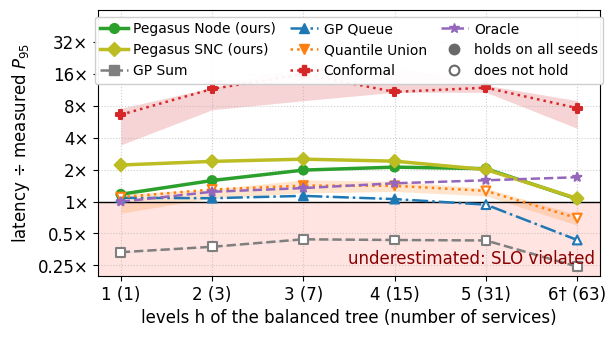

legend_inside: the legend hides 2 points or bands at its best location (upper left)
legend_inside: the legend hides 15 points or bands at its best location (upper center)


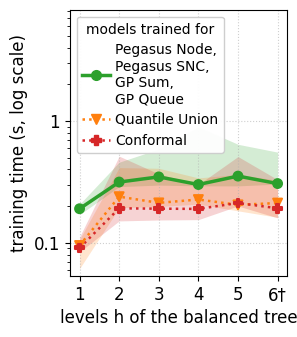

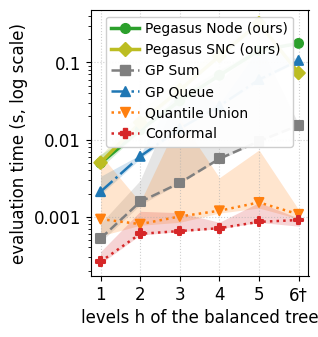

† preliminary: h = 6 from the 4 valid runs measured so far; the campaign is still measuring this tree
B.3 balanced fork-join trees, real data, small trees (160 to 256 px): leaves object and face detector, aggregators image transformer, one worker each, 36 to 48 held-out runs per tree,
Poisson arrivals at 50% utilization of the slowest service, 3 seeds (training draws)
legend_inside: the legend hides 4 points or bands at its best location (upper center)


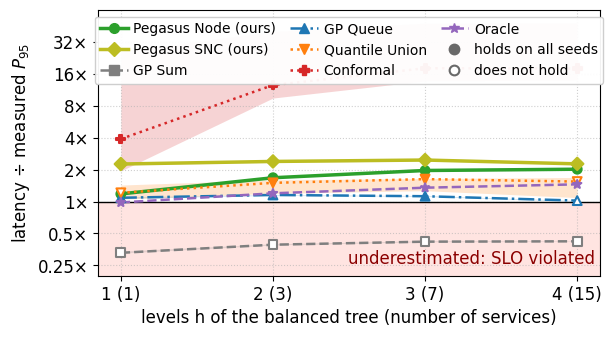

legend_inside: the legend hides 2 points or bands at its best location (upper center)
legend_inside: the legend hides 7 points or bands at its best location (upper center)


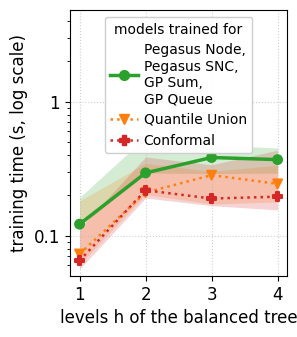

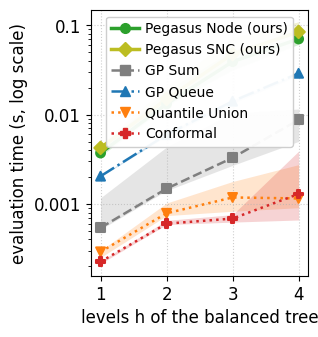

In [3]:
if "B.3" in tree_setup["skipped"]:
    print("B.3 skipped: not supported by the {} data".format(tree_source))
else:
    # the shapes (synthetic) or tree sets (real, VM_TREE_SETS in pegasus/real_data.py) in the order of `trees`, each with its levels h
    tree_shapes = {shape: [h for of, h in trees if of == shape] for shape, _ in trees}
    # the resolution range of a real tree set, from the experiment.yaml of its trees
    shape_text = {"balanced": "balanced", "large": "large trees (288 to 640 px)", "small": "small trees (160 to 256 px)"}
    mark = lambda shape, h: "†" if (shape, h) in tree_preliminary else ""   # a preliminary point (setup cell)
    tree_statistics, tree_times = {}, {}   # shape -> name -> coverage, tightness, holds, computed; shape -> name -> training, evaluation
    for shape, levels in tree_shapes.items():
        tree_statistics[shape] = sweep_statistics(tree_methods[shape], tree_truth[shape], levels, tree_seeds, confidence)
        tree_times[shape] = sweep_seconds(tree_seconds[shape], levels, tree_seeds)
        size_ticks = [f"{h}{mark(shape, h)} ({len(trees[(shape, h)][1])})" for h in levels]   # one row: the fixed layout of every figure
        if tree_source == "synthetic":
            title = (f"B.3 balanced fork-join trees, synthetic data: leaves s1, s2, aggregators s3, one worker each, "
                     f"{len(base.measured)} held-out configurations per seed,\n{workload['process']} arrivals at "
                     f"{tree_setup['tree_utilization']:.0%} utilization of the slowest service, {len(tree_seeds)} seeds")
        else:
            from pegasus.real_data import run_table
            # the utilization of the slowest service at which the campaign set the arrival rate of every run
            tree_utilization = sorted({float(u) for (of, _), experiment in tree_experiments.items() if of == shape
                                       for u in run_table(experiment)["utilization_asked"]})
            held_out = sorted({len(measured) for measured, _ in tree_truth[shape].values()})   # held-out runs of every tree
            runs_text = f"{held_out[0]}" if len(held_out) == 1 else f"{held_out[0]} to {held_out[-1]}"
            title = (f"B.3 balanced fork-join trees, real data, {shape_text[shape]}: leaves object and face detector, aggregators image "
                     f"transformer, one worker each, {runs_text} held-out runs per tree,\nPoisson arrivals at "
                     f"{' and '.join(f'{u:.0%}' for u in tree_utilization)} utilization of the slowest service, {len(tree_seeds)} seeds (training draws)")
        tightness_and_time_figure(levels, tree_statistics[shape], tree_times[shape], "levels h of the balanced tree (number of services)",
                                  title, p_label, tick_labels=size_ticks, log_x=False,
                                  name=f"b3_trees_{tree_source}" if shape == "balanced" else f"b3_trees_{tree_source}_{shape}",
                                  # the two time figures side by side in the width of one: too narrow for "h (N)" at every tick, and the
                                  # tightness figure already gives N for every h
                                  time_halves=("levels h of the balanced tree", [f"{h}{mark(shape, h)}" for h in levels]))
        for (of, h), runs in tree_preliminary.items():
            if of == shape:
                print(f"† preliminary: h = {h} from the {runs} valid runs measured so far; the campaign is still measuring this tree")

In [4]:
if "B.3" in tree_setup["skipped"]:
    print("B.3 skipped: not supported by the {} data".format(tree_source))
else:
    for shape, levels in tree_shapes.items():
        tree_label = lambda h: f"h = {h}{mark(shape, h)} ({len(trees[(shape, h)][1])})"   # levels (number of services)
        print(f"{shape_text[shape].capitalize()} ({tree_source} data; tightness, median over the seeds; ● holds, ○ does not):")
        display(sweep_table(levels, tree_statistics[shape], sweep_competitors + ["Oracle"], tree_label, tree_truth[shape], tree_seeds))
        print("Training and evaluation time (s, median over the seeds):")
        display(time_table(levels, tree_times[shape], sweep_competitors, tree_label))

Large trees (288 to 640 px) (real data; tightness, median over the seeds; ● holds, ○ does not):


,h = 1 (1),h = 2 (3),h = 3 (7),h = 4 (15),h = 5 (31),h = 6† (63)
Pegasus Node (ours),1.17× ●,1.58× ●,1.98× ●,2.11× ●,2.04× ●,1.06× ●
Pegasus SNC (ours),2.21× ●,2.39× ●,2.51× ●,2.40× ●,2.00× ●,1.07× ●
GP Sum,0.33× ○,0.37× ○,0.44× ○,0.43× ○,0.43× ○,0.24× ○
GP Queue,1.08× ●,1.07× ●,1.13× ●,1.05× ●,0.93× ○,0.43× ○
Quantile Union,1.10× ○,1.30× ○,1.41× ●,1.41× ●,1.26× ○,0.70× ○
Conformal,6.57× ●,11.48× ●,15.85× ●,10.77× ●,11.80× ●,7.58× ●
Oracle,1.00× ●,1.24× ●,1.34× ●,1.48× ●,1.58× ●,1.69× ●
measured (s),0.525,0.64,0.508,0.449,1.01,2.05


Training and evaluation time (s, median over the seeds):


,h = 1 (1),h = 2 (3),h = 3 (7),h = 4 (15),h = 5 (31),h = 6† (63)
"training: Pegasus Node (ours), Pegasus SNC (ours), GP Sum, GP Queue",0.19,0.32,0.35,0.3,0.35,0.31
training: Quantile Union,0.095,0.24,0.21,0.23,0.2,0.21
training: Conformal,0.091,0.19,0.19,0.19,0.21,0.19
evaluation: Pegasus Node (ours),0.005,0.013,0.032,0.068,0.14,0.18
evaluation: Pegasus SNC (ours),0.005,0.017,0.044,0.12,0.32,0.073
evaluation: GP Sum,0.00052,0.0016,0.0027,0.0057,0.0095,0.015
evaluation: GP Queue,0.0021,0.0061,0.014,0.027,0.06,0.11
evaluation: Quantile Union,0.00093,0.0008,0.001,0.0012,0.0015,0.0011
evaluation: Conformal,0.00026,0.0006,0.00065,0.00071,0.00086,0.00091


Small trees (160 to 256 px) (real data; tightness, median over the seeds; ● holds, ○ does not):


,h = 1 (1),h = 2 (3),h = 3 (7),h = 4 (15)
Pegasus Node (ours),1.18× ●,1.67× ●,1.96× ●,2.01× ●
Pegasus SNC (ours),2.25× ●,2.38× ●,2.46× ●,2.26× ●
GP Sum,0.33× ○,0.39× ○,0.42× ○,0.42× ○
GP Queue,1.08× ●,1.15× ●,1.12× ●,1.02× ○
Quantile Union,1.21× ○,1.50× ●,1.62× ●,1.54× ○
Conformal,3.88× ●,12.49× ●,17.99× ●,17.85× ●
Oracle,0.98× ●,1.19× ●,1.35× ●,1.45× ●
measured (s),0.108,0.123,0.14,0.19


Training and evaluation time (s, median over the seeds):


,h = 1 (1),h = 2 (3),h = 3 (7),h = 4 (15)
"training: Pegasus Node (ours), Pegasus SNC (ours), GP Sum, GP Queue",0.12,0.29,0.38,0.37
training: Quantile Union,0.073,0.21,0.28,0.24
training: Conformal,0.065,0.22,0.19,0.2
evaluation: Pegasus Node (ours),0.0037,0.013,0.039,0.07
evaluation: Pegasus SNC (ours),0.0042,0.015,0.048,0.084
evaluation: GP Sum,0.00054,0.0015,0.0033,0.0088
evaluation: GP Queue,0.002,0.006,0.014,0.029
evaluation: Quantile Union,0.00029,0.00079,0.0012,0.0012
evaluation: Conformal,0.00023,0.0006,0.00069,0.0013


#### Why the accuracy drops with depth: the services slow each other down

**Claim.** In a deep tree the services process an item more slowly than in their benchmark, and the slowdown grows with the
number of other services processing at the same time, not with the average load of the machine. Every frame reaches all
leaves at the same moment, so the deeper the tree, the more services compute together. The methods are trained on the
benchmarks, which measured every service alone, so they predict the speed of the benchmark.

- *Slowdown* of a service in a run: its mean processing time in the tree divided by that of its grid benchmark at the
  same configuration (`VM_TREE_BENCHMARKS`; the median over the benchmarks at u = 0.4, 0.6 and 0.8, whose processing
  times do not depend on the load on this machine). A slowdown of 1 means as fast as in the benchmark.
- *Concurrency* $c$ of a service in a run: the time-weighted mean number of the other services of the tree that are
  processing while the service processes an item (`trace_steps.csv`).
- *Data:* every run of both tree sets in `statics/results_milos_v2/b3-vm/` with $h$ = 1 to 6 whose services were
  throttled for less than `TREE_THROTTLE_LIMIT` (`tree_slowdowns` in `pegasus/evaluation.py`). This includes the small
  trees with $h$ = 5 and 6, which the evaluation above leaves out because their camera fell behind: the camera delays
  the frames before they reach the services, not the processing. The large tree with $h$ = 6 is preliminary (†).
- *Likely cause:* contention for a resource that all services of the machine share, most likely the memory interface.
  The testbed did not record hardware counters, so the data cannot confirm it.

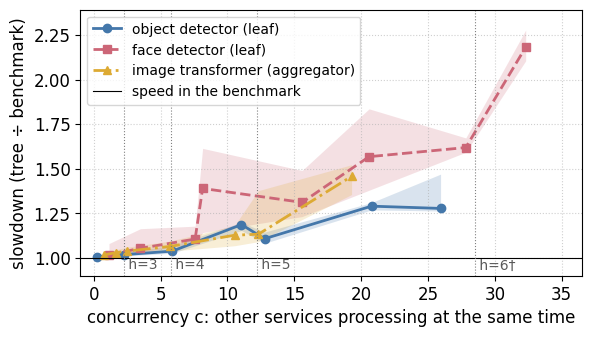

Large trees, per height (median over the services and runs):


,runs,concurrency c,slowdown,"slowdown, 90th percentile"
h,,,,
h = 1,48,0.0,1.00,1.00
h = 2,48,0.7,1.01,1.02
h = 3,48,2.3,1.02,1.06
h = 4,48,5.8,1.05,1.12
h = 5,48,12.2,1.11,1.36
h = 6†,4,28.5,1.46,2.19


In the large trees, a service saw a median concurrency of 5.8 other services at $h$ = 4 and 12.2 at $h$ = 5, with a median slowdown of 1.05 and 1.11. Within one height, where the topology and the average load of the machine are the same, a service that saw more concurrency was slowed more: Spearman's ρ between concurrency and slowdown is +0.67 at $h$ = 4, +0.85 at $h$ = 5, +0.92 at $h$ = 6†. Over both tree sets, the median slowdown is 1.02 at $c$ ≤ 4 and 1.46 at $c$ > 16.

In [5]:
# B.3 diagnosis: the slowdown of every service against the concurrency it saw (tree_slowdowns in pegasus/evaluation.py),
# both tree sets with h = 1 to 6 (statics/results_milos_v2/b3-vm/); not cached, because it takes only seconds
if tree_source == "real":
    from scipy.stats import spearmanr
    from pegasus.evaluation import slowdown_figure, tree_slowdowns
    from pegasus.real_data import RESULTS_V2, VM_TREE_SETS, VM_V2
    slowdown_experiments = {(tree_set, h): f"{VM_V2.name}/{prefix}{h}" for tree_set, (prefix, _) in VM_TREE_SETS.items()
                            for h in range(1, 7) if (RESULTS_V2 / VM_V2.name / f"{prefix}{h}").is_dir()}
    slowdowns = tree_slowdowns(slowdown_experiments)   # one row per run and service
    large = slowdowns[slowdowns["tree_set"] == "large"]
    # where the heights of the large trees lie: the median concurrency of their services
    large_concurrency = large.groupby("h")["concurrency"].median()
    slowdown_figure(slowdowns, {f"h={h}{mark('large', h)}": c for h, c in large_concurrency.items() if h >= 3}, name="b3_slowdown_concurrency")

    by_height = large.groupby("h")
    print("Large trees, per height (median over the services and runs):")
    display(pd.DataFrame({"runs": by_height["run_id"].nunique(), "concurrency c": by_height["concurrency"].median().round(1),
                          "slowdown": by_height["slowdown"].median().round(2),
                          "slowdown, 90th percentile": by_height["slowdown"].quantile(0.9).round(2)},
                         ).rename(index=lambda h: f"h = {h}{mark('large', h)}"))
    rho = {h: spearmanr(group["concurrency"], group["slowdown"])[0] for h, group in by_height if h >= 4}
    few, many = slowdowns["concurrency"] <= 4, slowdowns["concurrency"] > 16
    display(Markdown(
        f"In the large trees, a service saw a median concurrency of {large_concurrency[4]:.1f} other services at $h$ = 4 and "
        f"{large_concurrency[5]:.1f} at $h$ = 5, with a median slowdown of {by_height['slowdown'].median()[4]:.2f} and "
        f"{by_height['slowdown'].median()[5]:.2f}. Within one height, where the topology and the average load of the machine are "
        f"the same, a service that saw more concurrency was slowed more: Spearman's ρ between concurrency and slowdown is "
        + ", ".join(f"{value:+.2f} at $h$ = {h}{mark('large', h)}" for h, value in rho.items())
        + f". Over both tree sets, the median slowdown is {slowdowns.loc[few, 'slowdown'].median():.2f} at $c$ ≤ 4 and "
        f"{slowdowns.loc[many, 'slowdown'].median():.2f} at $c$ > 16."))

**Reading the figure.** Horizontal axis: the concurrency $c$ of a service in a run. Vertical axis: its slowdown. One
line per service type: the median slowdown of its runs in every bin of $c$ (0–1, 1–2, 2–4, 4–8, 8–12, 12–16, 16–24,
24–32 and 32–48 services, `CONCURRENCY_BINS`), drawn at the median $c$ of the bin, with the band from the 10th to the
90th percentile; a bin with fewer than 10 runs is left out. The black line at 1 is the speed of the benchmark, and the
dotted vertical lines mark the median concurrency of the large trees with $h$ = 3 to 6.

Look at where the lines leave 1. Up to a few concurrent services, every service runs at the speed of its benchmark; with
about ten and more, all three slow down, the face detector the most. The large trees reach that range from $h$ = 4 on,
which is where the methods start to lose accuracy (figure above): they predict the speed of the benchmark, and a slower
service also queues longer at the arrival rate the campaign set, so the latency grows more than the slowdown alone.

Two limits of the figure. A bin pools different heights, configurations and both tree sets, so the lines are not smooth.
And the concurrency is partly an effect of the slowdown, not only its cause: a slower service overlaps with more others.